In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AML_Project"

OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

FORENSIC_PATH = os.path.join(
    OUTPUT_PATH,
    "forensic"
)

FA05_PATH = os.path.join(
    FORENSIC_PATH,
    "FA05"
)

os.makedirs(FA05_PATH, exist_ok=True)

print("FA05 output folder:")
print(FA05_PATH)

FA05 output folder:
/content/drive/MyDrive/AML_Project/outputs/forensic/FA05


In [ ]:
TRANSACTION_FILE = os.path.join(
    OUTPUT_PATH,
    "integrated_transaction_risk_results.csv"
)

df = pd.read_csv(TRANSACTION_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (149994, 35)


In [ ]:
repeated_file = os.path.join(
    FORENSIC_PATH,
    "FA03",
    "repeated_transactions.csv"
)

repeated_df = pd.read_csv(repeated_file)

print(
    "Repeated transaction records:",
    len(repeated_df)
)

Repeated transaction records: 16


In [ ]:
benford_file = os.path.join(
    FORENSIC_PATH,
    "FA02",
    "benford_screened_transactions.csv"
)

benford_df = pd.read_csv(benford_file)

print(
    "Benford-screened transactions:",
    len(benford_df)
)

Benford-screened transactions: 82391


In [ ]:
outlier_file = os.path.join(
    FORENSIC_PATH,
    "FA03",
    "amount_outliers.csv"
)

outlier_df = pd.read_csv(outlier_file)

print(
    "Amount outlier transactions:",
    len(outlier_df)
)

Amount outlier transactions: 16681


In [ ]:
benford_ids = set(
    benford_df["transaction_id"]
)

df["benford_flag"] = (
    df["transaction_id"]
    .isin(benford_ids)
    .astype(int)
)

print(
    "Transactions with Benford flag:",
    df["benford_flag"].sum()
)

Transactions with Benford flag: 82391


In [ ]:
repeated_ids = set(
    repeated_df["transaction_id"]
)

df["repeated_transaction_flag"] = (
    df["transaction_id"]
    .isin(repeated_ids)
    .astype(int)
)

print(
    "Repeated transaction flags:",
    df["repeated_transaction_flag"].sum()
)

Repeated transaction flags: 16


In [ ]:
outlier_ids = set(
    outlier_df["transaction_id"]
)

df["amount_outlier_flag"] = (
    df["transaction_id"]
    .isin(outlier_ids)
    .astype(int)
)

print(
    "Amount outlier flags:",
    df["amount_outlier_flag"].sum()
)

Amount outlier flags: 16681


In [ ]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour

print("Timestamp features prepared.")

Timestamp features prepared.


In [ ]:
daily_counts = (
    df.groupby("date")["transaction_id"]
      .count()
)

daily_mean = daily_counts.mean()
daily_std = daily_counts.std()

daily_threshold = (
    daily_mean +
    2 * daily_std
)

spike_dates = set(
    daily_counts[
        daily_counts > daily_threshold
    ].index
)

df["temporal_spike_flag"] = (
    df["date"]
    .isin(spike_dates)
    .astype(int)
)

print("Temporal spike days:", len(spike_dates))
print(
    "Transactions occurring on spike days:",
    df["temporal_spike_flag"].sum()
)

Temporal spike days: 0
Transactions occurring on spike days: 0


In [ ]:
df["sequential_risk_normalized"] = (
    df["sequential_risk"]
    .clip(0, 100)
)

df["spatial_risk_normalized"] = (
    df["spatial_risk"]
    .clip(0, 100)
)

print("Risk values normalized to 0–100.")

Risk values normalized to 0–100.


In [ ]:
df["forensic_evidence_score"] = (

    # Forensic indicators
    df["benford_flag"] * 15

    + df["repeated_transaction_flag"] * 20

    + df["amount_outlier_flag"] * 25

    + df["temporal_spike_flag"] * 15

    # Existing SASDM evidence
    + df["sequential_risk_normalized"] * 0.15

    + df["spatial_risk_normalized"] * 0.10
)

# Ensure score remains between 0 and 100
df["forensic_evidence_score"] = (
    df["forensic_evidence_score"]
    .clip(0, 100)
)

print("Forensic evidence score calculated.")

print(
    df["forensic_evidence_score"].describe()
)

Forensic evidence score calculated.
count    149994.000000
mean         12.964269
std          11.250929
min           0.000000
25%           0.000000
50%          15.000000
75%          19.500000
max          65.000000
Name: forensic_evidence_score, dtype: float64


In [ ]:
def assign_priority(score):

    if score >= 75:
        return "Critical"

    elif score >= 50:
        return "High"

    elif score >= 25:
        return "Moderate"

    else:
        return "Low"


df["investigation_priority"] = (
    df["forensic_evidence_score"]
    .apply(assign_priority)
)

print("Investigation priorities assigned.")

Investigation priorities assigned.


In [ ]:
priority_distribution = (
    df["investigation_priority"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High", "Critical"],
        fill_value=0
    )
    .reset_index()
)

priority_distribution.columns = [
    "investigation_priority",
    "transaction_count"
]

display(priority_distribution)

,investigation_priority,transaction_count
0,Low,127866
1,Moderate,21228
2,High,900
3,Critical,0


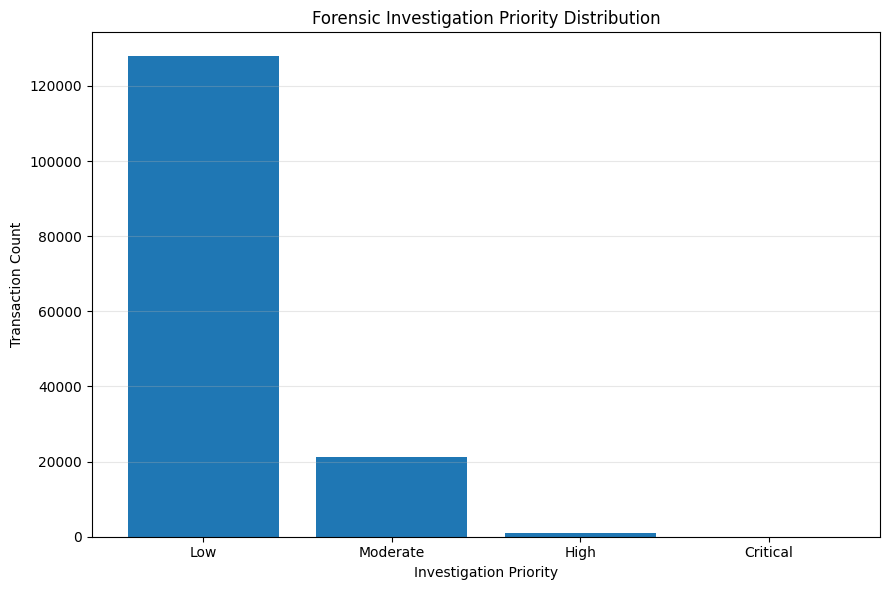

In [ ]:
plt.figure(figsize=(9, 6))

plt.bar(
    priority_distribution["investigation_priority"],
    priority_distribution["transaction_count"]
)

plt.xlabel("Investigation Priority")
plt.ylabel("Transaction Count")
plt.title("Forensic Investigation Priority Distribution")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FA05_PATH,
        "investigation_priority_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
investigation_columns = [
    "transaction_id",
    "sender",
    "receiver",
    "receiver_name",
    "transaction_type",
    "amount",
    "timestamp",
    "city",
    "state",
    "fraud_type",
    "is_fraud",

    # SASDM evidence
    "sequential_risk",
    "spatial_risk",
    "integrated_risk_score",

    # Forensic evidence
    "benford_flag",
    "repeated_transaction_flag",
    "amount_outlier_flag",
    "temporal_spike_flag",

    # Final forensic view
    "forensic_evidence_score",
    "investigation_priority"
]

top_investigation_candidates = (
    df[
        investigation_columns
    ]
    .sort_values(
        [
            "forensic_evidence_score",
            "integrated_risk_score"
        ],
        ascending=False
    )
    .head(100)
)

display(top_investigation_candidates.head(20))

,transaction_id,sender,receiver,receiver_name,transaction_type,amount,timestamp,city,state,fraud_type,is_fraud,sequential_risk,spatial_risk,integrated_risk_score,benford_flag,repeated_transaction_flag,amount_outlier_flag,temporal_spike_flag,forensic_evidence_score,investigation_priority
4999,FRAUD001302,CUST00161,CUST02586,CUST02241,Transfer,121086.62,2026-01-06 15:22:00,Jaipur,Rajasthan,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
5053,FRAUD001342,CUST00163,CUST02308,CUST00256,Transfer,123781.53,2026-01-06 03:19:00,Hyderabad,Telangana,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
10960,FRAUD001365,CUST00354,CUST01947,CUST04382,Transfer,134157.91,2026-01-06 04:33:00,Kolkata,West Bengal,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
11292,TX00022768,CUST00366,CUST02628,CUST02628,Transfer,44229.00,2026-01-02 13:22:27,Bengaluru,Karnataka,Normal,0,100.0,100.0,100.0,1,0,1,0,65.0,High
13039,FRAUD001325,CUST00423,CUST04245,CUST01604,Transfer,118753.23,2026-01-06 06:02:00,Chennai,Tamil Nadu,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
18230,FRAUD001446,CUST00572,CUST03573,CUST04640,Transfer,130542.03,2026-01-06 17:54:00,Jaipur,Rajasthan,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
19100,TX00108961,CUST00602,CUST01922,CUST01922,Transfer,44538.00,2026-01-06 21:11:59,Kolkata,West Bengal,Normal,0,100.0,100.0,100.0,1,0,1,0,65.0,High
19298,FRAUD001261,CUST00609,CUST04687,CUST03057,Transfer,139341.20,2026-01-06 11:04:00,Kolkata,West Bengal,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High
29502,TX00089071,CUST00949,CUST01163,CUST01163,Transfer,47979.00,2026-01-05 07:45:17,Kochi,Kerala,Normal,0,100.0,100.0,100.0,1,0,1,0,65.0,High
32514,FRAUD001426,CUST01050,CUST03106,CUST04925,Transfer,139134.91,2026-01-06 04:18:00,Kolkata,West Bengal,RapidGeographicMovement,1,100.0,100.0,100.0,1,0,1,0,65.0,High


In [ ]:
def generate_evidence(row):

    evidence = []

    if row["benford_flag"] == 1:
        evidence.append("Benford deviation")

    if row["repeated_transaction_flag"] == 1:
        evidence.append("Repeated transaction")

    if row["amount_outlier_flag"] == 1:
        evidence.append("Amount outlier")

    if row["temporal_spike_flag"] == 1:
        evidence.append("Temporal spike")

    if row["sequential_risk"] >= 60:
        evidence.append("High sequential risk")

    if row["spatial_risk"] >= 60:
        evidence.append("High spatial risk")

    if not evidence:
        return "No major forensic indicators"

    return "; ".join(evidence)


top_investigation_candidates["evidence_summary"] = (
    top_investigation_candidates
    .apply(generate_evidence, axis=1)
)

display(
    top_investigation_candidates[
        [
            "transaction_id",
            "amount",
            "forensic_evidence_score",
            "investigation_priority",
            "evidence_summary"
        ]
    ].head(20)
)

,transaction_id,amount,forensic_evidence_score,investigation_priority,evidence_summary
4999,FRAUD001302,121086.62,65.0,High,Benford deviation; Amount outlier; High sequen...
5053,FRAUD001342,123781.53,65.0,High,Benford deviation; Amount outlier; High sequen...
10960,FRAUD001365,134157.91,65.0,High,Benford deviation; Amount outlier; High sequen...
11292,TX00022768,44229.00,65.0,High,Benford deviation; Amount outlier; High sequen...
13039,FRAUD001325,118753.23,65.0,High,Benford deviation; Amount outlier; High sequen...
18230,FRAUD001446,130542.03,65.0,High,Benford deviation; Amount outlier; High sequen...
19100,TX00108961,44538.00,65.0,High,Benford deviation; Amount outlier; High sequen...
19298,FRAUD001261,139341.20,65.0,High,Benford deviation; Amount outlier; High sequen...
29502,TX00089071,47979.00,65.0,High,Benford deviation; Amount outlier; High sequen...
32514,FRAUD001426,139134.91,65.0,High,Benford deviation; Amount outlier; High sequen...


In [ ]:
priority_evaluation = (
    df.groupby("investigation_priority")
      .agg(
          transaction_count=("transaction_id", "count"),
          fraud_count=("is_fraud", "sum")
      )
      .reindex(
          ["Low", "Moderate", "High", "Critical"]
      )
      .reset_index()
)

priority_evaluation["fraud_rate_percent"] = (
    priority_evaluation["fraud_count"]
    /
    priority_evaluation["transaction_count"]
    * 100
)

display(priority_evaluation)

,investigation_priority,transaction_count,fraud_count,fraud_rate_percent
0,Low,127866.0,242.0,0.189261
1,Moderate,21228.0,985.0,4.640098
2,High,900.0,223.0,24.777778
3,Critical,NaN,NaN,NaN


In [ ]:
indicator_summary = pd.DataFrame({
    "indicator": [
        "Benford screening",
        "Repeated transaction",
        "Amount outlier",
        "Temporal spike",
        "Sequential risk >= 60",
        "Spatial risk >= 60"
    ],
    "flagged_transactions": [
        int(df["benford_flag"].sum()),
        int(df["repeated_transaction_flag"].sum()),
        int(df["amount_outlier_flag"].sum()),
        int(df["temporal_spike_flag"].sum()),
        int((df["sequential_risk"] >= 60).sum()),
        int((df["spatial_risk"] >= 60).sum())
    ]
})

display(indicator_summary)

,indicator,flagged_transactions
0,Benford screening,82391
1,Repeated transaction,16
2,Amount outlier,16681
3,Temporal spike,0
4,Sequential risk >= 60,6767
5,Spatial risk >= 60,3447


In [ ]:
indicator_summary.to_csv(
    os.path.join(
        FA05_PATH,
        "forensic_indicator_summary.csv"
    ),
    index=False
)

priority_distribution.to_csv(
    os.path.join(
        FA05_PATH,
        "investigation_priority_distribution.csv"
    ),
    index=False
)

priority_evaluation.to_csv(
    os.path.join(
        FA05_PATH,
        "priority_ground_truth_evaluation.csv"
    ),
    index=False
)

print("Summary files saved.")

Summary files saved.


In [ ]:
top_investigation_candidates.to_csv(
    os.path.join(
        FA05_PATH,
        "top_investigation_candidates.csv"
    ),
    index=False
)

print(
    "Saved: top_investigation_candidates.csv"
)

Saved: top_investigation_candidates.csv


In [ ]:
final_forensic_columns = [
    "transaction_id",
    "sender",
    "receiver",
    "receiver_name",
    "is_merchant",
    "transaction_type",
    "amount",
    "timestamp",
    "atm_id",
    "city",
    "state",
    "latitude",
    "longitude",
    "fraud_type",
    "pattern_id",

    # Existing SASDM evidence
    "sequential_risk",
    "spatial_risk",
    "integrated_risk_score",
    "risk_category",
    "predicted_fraud",

    # Forensic evidence
    "benford_flag",
    "repeated_transaction_flag",
    "amount_outlier_flag",
    "temporal_spike_flag",

    # Final forensic result
    "forensic_evidence_score",
    "investigation_priority"
]

final_forensic_results = df[
    final_forensic_columns
].copy()

final_forensic_results.to_csv(
    os.path.join(
        FA05_PATH,
        "final_forensic_transaction_results.csv"
    ),
    index=False
)

print(
    "Saved: final_forensic_transaction_results.csv"
)

Saved: final_forensic_transaction_results.csv


In [ ]:
fa05_summary = pd.DataFrame({
    "metric": [
        "Total transactions analysed",
        "Benford-screened transactions",
        "Repeated transactions",
        "Amount outliers",
        "Temporal spike transactions",
        "High-priority transactions",
        "Critical-priority transactions",
        "Ground-truth fraud transactions",
        "Maximum forensic evidence score"
    ],
    "value": [
        len(df),
        int(df["benford_flag"].sum()),
        int(df["repeated_transaction_flag"].sum()),
        int(df["amount_outlier_flag"].sum()),
        int(df["temporal_spike_flag"].sum()),
        int(
            (
                df["investigation_priority"] == "High"
            ).sum()
        ),
        int(
            (
                df["investigation_priority"] == "Critical"
            ).sum()
        ),
        int(df["is_fraud"].sum()),
        df["forensic_evidence_score"].max()
    ]
})

display(fa05_summary)

fa05_summary.to_csv(
    os.path.join(
        FA05_PATH,
        "FA05_summary.csv"
    ),
    index=False
)

print("FA-05 completed successfully.")

,metric,value
0,Total transactions analysed,149994.0
1,Benford-screened transactions,82391.0
2,Repeated transactions,16.0
3,Amount outliers,16681.0
4,Temporal spike transactions,0.0
5,High-priority transactions,900.0
6,Critical-priority transactions,0.0
7,Ground-truth fraud transactions,1450.0
8,Maximum forensic evidence score,65.0


FA-05 completed successfully.


# FA_05 — Forensic Risk Integration & Investigation

## Financial Crime Analytics & Money Laundering Investigation Platform

### Objective

This notebook integrates the forensic indicators developed in FA-02,
FA-03 and FA-04 with the existing SASDM sequential and spatial risk
signals.

The objective is to create an investigation-oriented view of suspicious
transactions.

### Evidence Sources

#### Existing SASDM Evidence
- Sequential Risk
- Spatial Risk
- Rapid Geographic Movement
- Integrated Risk Score
- Risk Category

#### Forensic Evidence
- Benford Screening
- Repeated Transaction Indicator
- Amount Outlier Indicator
- Temporal Activity Indicators

### Important Principle

The resulting forensic score is an investigation prioritization tool.
It does not constitute proof of fraud.

Ground-truth fraud labels are used only for evaluation because the
project uses a controlled synthetic dataset.